# Congratulations, You Have a DAG. Now What?

**Authored by**: Camilo Saldarriaga, Alexander Fengler, Francesco Muia

**Monetary Policy Surprises and Equity Returns** (Bernanke & Kuttner 2005)

We take a well-known causal structure from the monetary-economics literature, instantiate it with three competing functional forms (linear, regime-switching, nonlinear), and use PyMC to recover the correct specification via LOO model comparison. Each functional form generates different results, and choosing the right one can be the edge that separates you from competitors trading the same insight.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt
import json
import os

RANDOM_SEED = 42
N = 2000
FIG_DIR = os.path.join(os.getcwd(), "figures")
os.makedirs(FIG_DIR, exist_ok=True)

rng = np.random.default_rng(RANDOM_SEED)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 12})
az.style.use("arviz-darkgrid")
%config InlineBackend.figure_format = "retina"

## The DAG: Bernanke-Kuttner Channels

Two channels transmit monetary policy surprises to equity returns:

```mermaid
graph LR
    MN["Macro news (MN)"] --> MP["MP_surp"]
    MN --> ECF["ΔECF"]
    MP --> DR["ΔDR"]
    MP --> ECF
    MP --> Req["R_eq"]
    DR --> Req
    ECF --> Req
    RS["Risk sentiment (RS)"] --> DR
    RS --> Req
```

| Variable | Symbol | Interpretation |
|----------|--------|----------------|
| Monetary policy surprise | MP_surp | Futures-implied surprise in target rate |
| Change in discount rates | ΔDR | Change in risk-free discounting / yields |
| Change in expected cash flows | ΔECF | Cash-flow news / expected earnings |
| Risk sentiment | RS | Time-varying risk appetite |
| Macro news | MN | Information moving both policy and cash flows |
| Equity returns | R_eq | Equity index return |

The structural model:

$$MP_{\text{surp}} = f_0(MN) + \varepsilon_0$$
$$\Delta DR = f_1(MP_{\text{surp}}, RS) + \varepsilon_1$$
$$\Delta ECF = f_2(MP_{\text{surp}}, MN) + \varepsilon_2$$
$$R_{eq} = f_3(\Delta DR, \Delta ECF, RS, MP_{\text{surp}}) + \varepsilon_3$$

The DAG is the same across all three specifications. The question is: **what are $f_0, f_1, f_2, f_3$?**

## Data Generating Process

We generate synthetic data from a regime-switching DGP that embeds sharp asymmetries between monetary-policy tightening and easing.

Rather than hand-coding a separate numpy function, we express the DGP directly as a PyMC model. A PyMC model is not just an inference tool — it is a fully generative probabilistic program. Every `pm.Model()` defines a joint distribution over all its variables. When you call `sample_prior_predictive()`, PyMC samples parameters from their prior distributions and propagates forward through the structural equations to generate data.

The `pm.do()` operator — inspired by Pearl's *do*-calculus — intervenes on the model by replacing specified random variables with fixed constants, effectively clamping them to known values. This lets us use the exact same PyMC model for two purposes:

1. **Data generation**: Fix all parameters to ground-truth values with `pm.do()`, then call `sample_prior_predictive()` to draw synthetic data from the model's forward pass.
2. **Inference**: Condition on observed data and call `pm.sample()` to recover the posterior distribution over parameters.

There is no gap between the assumed model structure and the data-generating process — they are literally the same PyMC program.

In [2]:
# --- Generative regime model (ground-truth DGP as a PyMC model) ---
with pm.Model() as regime_dgp:
    # Exogenous variables
    RS = pm.Normal("RS", 0, 1, shape=N)
    MN = pm.Normal("MN", 0, 1, shape=N)
    MP_surp = pm.Normal("MP_surp", mu=0.5 * MN, sigma=1.5, shape=N)
    tight = pt.switch(MP_surp > 0, 1.0, 0.0)

    # DR channel: regime-dependent slopes
    a1_t = pm.Normal("a1_tight", 0, 2)
    a1_e = pm.Normal("a1_ease", 0, 2)
    a2   = pm.Normal("a2", 0, 2)
    sigma_dr = pm.HalfNormal("sigma_dr", 2)
    DR = pm.Normal("DR",
        mu=(a1_t * tight + a1_e * (1 - tight)) * MP_surp + a2 * RS,
        sigma=sigma_dr, shape=N)

    # ECF channel: regime-dependent slopes
    b1_t = pm.Normal("b1_tight", 0, 2)
    b1_e = pm.Normal("b1_ease", 0, 2)
    b2   = pm.Normal("b2", 0, 2)
    sigma_ecf = pm.HalfNormal("sigma_ecf", 2)
    ECF = pm.Normal("ECF",
        mu=(b1_t * tight + b1_e * (1 - tight)) * MP_surp + b2 * MN,
        sigma=sigma_ecf, shape=N)

    # R_eq: explicit latent stress indicator
    # (During inference, Model B marginalizes over this via pm.Mixture)
    c1 = pm.Normal("c1", 0, 2)
    c2 = pm.Normal("c2", 0, 2)
    c3 = pm.Normal("c3", 0, 2)
    c_stress = pm.Normal("c_stress", 0, 5)
    p_stress = pm.Beta("p_stress", 2, 10)
    sigma_req = pm.HalfNormal("sigma_req", 2)
    stress = pm.Bernoulli("stress", p=p_stress, shape=N)
    base_mu = c1 * DR + c2 * ECF + c3 * RS
    R_eq = pm.Normal("R_eq",
        mu=base_mu + stress * c_stress * pt.abs(MP_surp),
        sigma=sigma_req, shape=N)

In [3]:
# Fix parameters to ground-truth values using pm.do()
true_params = {
    "a1_tight": 1.8, "a1_ease": 0.3, "a2": 0.6, "sigma_dr": 0.7,
    "b1_tight": -0.2, "b1_ease": -1.0, "b2": 0.7, "sigma_ecf": 0.7,
    "c1": -0.6, "c2": 0.8, "c3": 0.5, "c_stress": -5.0,
    "p_stress": 0.159, "sigma_req": 0.8,
}

dgp_fixed = pm.do(regime_dgp, true_params)

with dgp_fixed:
    prior = pm.sample_prior_predictive(samples=1, random_seed=RANDOM_SEED)

df = pd.DataFrame({
    "RS": prior.prior["RS"].values.flatten(),
    "MN": prior.prior["MN"].values.flatten(),
    "MP_surp": prior.prior["MP_surp"].values.flatten(),
    "DR": prior.prior["DR"].values.flatten(),
    "ECF": prior.prior["ECF"].values.flatten(),
    "R_eq": prior.prior["R_eq"].values.flatten(),
    "stress": prior.prior["stress"].values.flatten(),
})
df.describe().round(2)

Sampling: [DR, ECF, MN, MP_surp, RS, R_eq, stress]


,RS,MN,MP_surp,DR,ECF,R_eq,stress
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,0.01,0.01,-0.07,0.90,0.55,-1.09,0.15
std,1.00,1.02,1.59,2.03,1.26,3.69,0.36
min,-3.47,-3.14,-5.42,-3.80,-3.60,-28.68,0.00
25%,-0.67,-0.71,-1.18,-0.50,-0.34,-2.17,0.00
50%,0.03,0.04,-0.10,0.46,0.46,-0.40,0.00
75%,0.68,0.72,0.96,1.95,1.33,1.06,0.00
max,3.02,3.27,6.16,12.53,5.33,5.52,1.00


C:\Users\camil\AppData\Local\Temp\ipykernel_103592\279157546.py:14: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


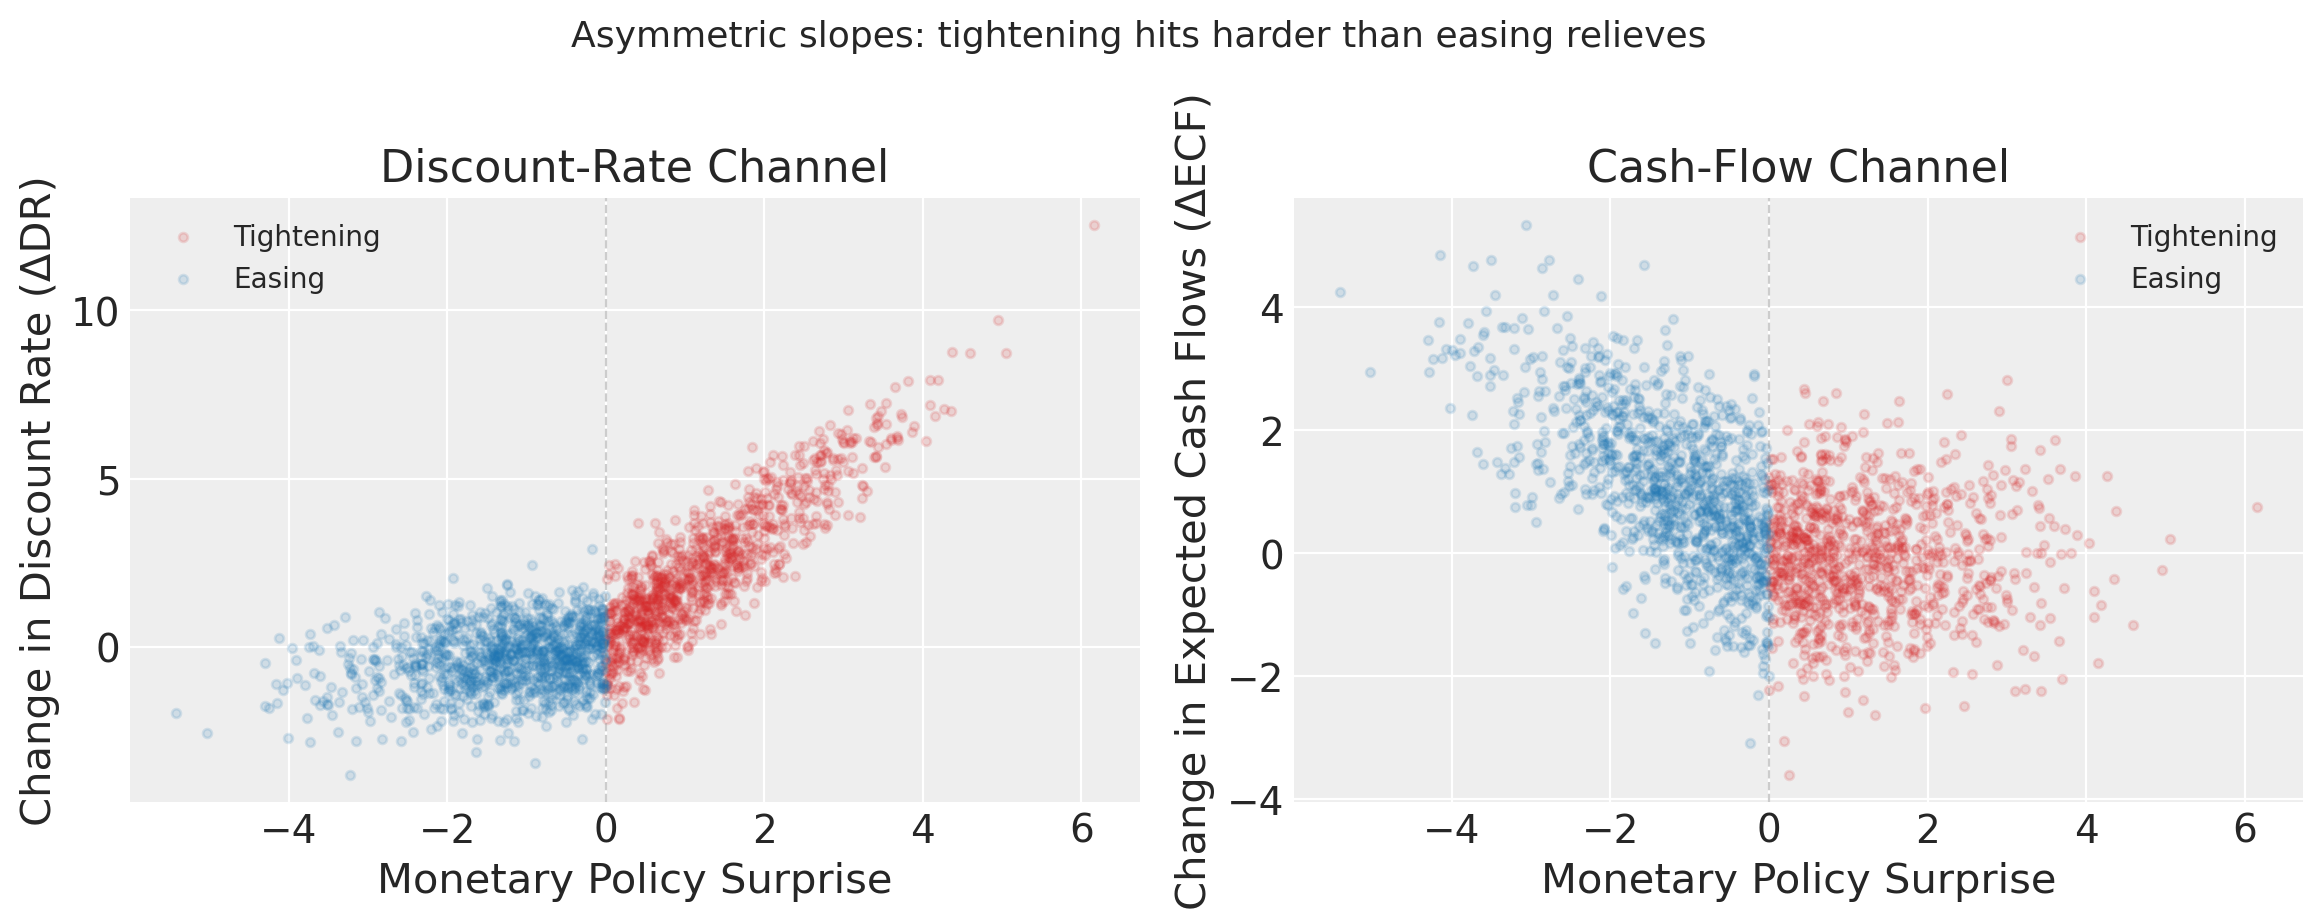

In [4]:
tightening_bool = df["MP_surp"].values > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, mask, color in [("Tightening", tightening_bool, "#d62728"), ("Easing", ~tightening_bool, "#1f77b4")]:
    axes[0].scatter(df["MP_surp"][mask], df["DR"][mask], alpha=0.15, s=10, label=label, color=color)
    axes[1].scatter(df["MP_surp"][mask], df["ECF"][mask], alpha=0.15, s=10, label=label, color=color)

axes[0].set(xlabel="Monetary Policy Surprise", ylabel="Change in Discount Rate (ΔDR)", title="Discount-Rate Channel")
axes[1].set(xlabel="Monetary Policy Surprise", ylabel="Change in Expected Cash Flows (ΔECF)", title="Cash-Flow Channel")
for ax in axes:
    ax.legend(fontsize=10, framealpha=0.9)
    ax.axvline(0, color="grey", ls="--", alpha=0.4, lw=0.8)
fig.suptitle("Asymmetric slopes: tightening hits harder than easing relieves", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig1_scatter_asymmetry.png"), dpi=150, bbox_inches="tight")
plt.show()

## PyMC Models

All three models encode the same DAG. They differ only in the functional forms of $f_1, f_2, f_3$.

In [5]:
from IPython.display import display, Markdown

In [6]:
# --- Model A: Linear ---
mp_vals = df["MP_surp"].values
rs_vals = df["RS"].values
mn_vals = df["MN"].values
dr_vals = df["DR"].values
ecf_vals = df["ECF"].values
req_vals = df["R_eq"].values

with pm.Model() as model_linear:
    # DR = a1*MP + a2*RS + noise
    a1 = pm.Normal("a1", mu=0, sigma=2)
    a2 = pm.Normal("a2", mu=0, sigma=2)
    sigma_dr = pm.HalfNormal("sigma_dr", sigma=2)
    pm.Normal("DR", mu=a1 * mp_vals + a2 * rs_vals, sigma=sigma_dr, observed=dr_vals)

    # ECF = b1*MP + b2*MN + noise
    b1 = pm.Normal("b1", mu=0, sigma=2)
    b2 = pm.Normal("b2", mu=0, sigma=2)
    sigma_ecf = pm.HalfNormal("sigma_ecf", sigma=2)
    pm.Normal("ECF", mu=b1 * mp_vals + b2 * mn_vals, sigma=sigma_ecf, observed=ecf_vals)

    # R_eq = c1*DR + c2*ECF + c3*RS + noise
    c1 = pm.Normal("c1", mu=0, sigma=2)
    c2 = pm.Normal("c2", mu=0, sigma=2)
    c3 = pm.Normal("c3", mu=0, sigma=2)
    sigma_req = pm.HalfNormal("sigma_req", sigma=2)
    pm.Normal("R_eq", mu=c1 * dr_vals + c2 * ecf_vals + c3 * rs_vals, sigma=sigma_req, observed=req_vals)

# Print mermaid dag
mermaid_str = pm.model_to_mermaid(model_linear)
display(Markdown(f"### Linear Model\n\n```mermaid\n{mermaid_str}\n```"))

### Linear Model

```mermaid
graph TD
%% Nodes:
DR([DR ~ Normal])
DR@{ shape: rounded }
style DR fill:#757575
ECF([ECF ~ Normal])
ECF@{ shape: rounded }
style ECF fill:#757575
R_eq([R_eq ~ Normal])
R_eq@{ shape: rounded }
style R_eq fill:#757575
a1([a1 ~ Normal])
a1@{ shape: rounded }
a2([a2 ~ Normal])
a2@{ shape: rounded }
b1([b1 ~ Normal])
b1@{ shape: rounded }
b2([b2 ~ Normal])
b2@{ shape: rounded }
c1([c1 ~ Normal])
c1@{ shape: rounded }
c2([c2 ~ Normal])
c2@{ shape: rounded }
c3([c3 ~ Normal])
c3@{ shape: rounded }
sigma_dr([sigma_dr ~ Halfnormal])
sigma_dr@{ shape: rounded }
sigma_ecf([sigma_ecf ~ Halfnormal])
sigma_ecf@{ shape: rounded }
sigma_req([sigma_req ~ Halfnormal])
sigma_req@{ shape: rounded }

%% Edges:
a1 --> DR
a2 --> DR
sigma_dr --> DR
b1 --> ECF
b2 --> ECF
sigma_ecf --> ECF
c1 --> R_eq
c2 --> R_eq
c3 --> R_eq
sigma_req --> R_eq

%% Plates:
subgraph "2000"
    DR
    R_eq
    ECF
end
```

In [7]:
# --- Model B: Regime-switching ---
tight = (mp_vals > 0).astype(float)

with pm.Model() as model_regime:
    # Discount-rate change channel: separate slope per regime
    a1_t = pm.Normal("a1_tight", mu=0, sigma=2)
    a1_e = pm.Normal("a1_ease", mu=0, sigma=2)
    a2   = pm.Normal("a2", mu=0, sigma=2)
    dr_mu = (a1_t * tight + a1_e * (1 - tight)) * mp_vals + a2 * rs_vals
    pm.Normal("DR", mu=dr_mu, sigma=pm.HalfNormal("sigma_dr", 2), observed=dr_vals)

    # Cash-flow change channel: regime-dependent slopes
    b1_t = pm.Normal("b1_tight", mu=0, sigma=2)
    b1_e = pm.Normal("b1_ease", mu=0, sigma=2)
    b2   = pm.Normal("b2", mu=0, sigma=2)
    ecf_mu = (b1_t * tight + b1_e * (1 - tight)) * mp_vals + b2 * mn_vals
    pm.Normal("ECF", mu=ecf_mu, sigma=pm.HalfNormal("sigma_ecf", 2), observed=ecf_vals)

    # Equity returns: latent stress mixture
    c1 = pm.Normal("c1", mu=0, sigma=2)
    c2 = pm.Normal("c2", mu=0, sigma=2)
    c3 = pm.Normal("c3", mu=0, sigma=2)
    c_stress = pm.Normal("c_stress", mu=0, sigma=5)
    p_stress = pm.Beta("p_stress", alpha=2, beta=10)
    sigma_req = pm.HalfNormal("sigma_req", sigma=2)
    base_mu = c1*dr_vals + c2*ecf_vals + c3*rs_vals
    pm.Mixture(
        "R_eq",
        w=pt.stack([1 - p_stress, p_stress]),
        comp_dists=[
            pm.Normal.dist(mu=base_mu, sigma=sigma_req),
            pm.Normal.dist(mu=base_mu + c_stress * np.abs(mp_vals), sigma=sigma_req),
        ],
        observed=req_vals,
    )

mermaid_str = pm.model_to_mermaid(model_regime)
display(Markdown(f"### Regime switching Model\n\n```mermaid\n{mermaid_str}\n```"))

### Regime switching Model

```mermaid
graph TD
%% Nodes:
DR([DR ~ Normal])
DR@{ shape: rounded }
style DR fill:#757575
ECF([ECF ~ Normal])
ECF@{ shape: rounded }
style ECF fill:#757575
R_eq([R_eq ~ Mixture])
R_eq@{ shape: rounded }
style R_eq fill:#757575
a1_ease([a1_ease ~ Normal])
a1_ease@{ shape: rounded }
a1_tight([a1_tight ~ Normal])
a1_tight@{ shape: rounded }
a2([a2 ~ Normal])
a2@{ shape: rounded }
b1_ease([b1_ease ~ Normal])
b1_ease@{ shape: rounded }
b1_tight([b1_tight ~ Normal])
b1_tight@{ shape: rounded }
b2([b2 ~ Normal])
b2@{ shape: rounded }
c1([c1 ~ Normal])
c1@{ shape: rounded }
c2([c2 ~ Normal])
c2@{ shape: rounded }
c3([c3 ~ Normal])
c3@{ shape: rounded }
c_stress([c_stress ~ Normal])
c_stress@{ shape: rounded }
p_stress([p_stress ~ Beta])
p_stress@{ shape: rounded }
sigma_dr([sigma_dr ~ Halfnormal])
sigma_dr@{ shape: rounded }
sigma_ecf([sigma_ecf ~ Halfnormal])
sigma_ecf@{ shape: rounded }
sigma_req([sigma_req ~ Halfnormal])
sigma_req@{ shape: rounded }

%% Edges:
a1_ease --> DR
a1_tight --> DR
a2 --> DR
sigma_dr --> DR
b1_ease --> ECF
b1_tight --> ECF
b2 --> ECF
sigma_ecf --> ECF
c1 --> R_eq
c2 --> R_eq
c3 --> R_eq
c_stress --> R_eq
p_stress --> R_eq
sigma_req --> R_eq

%% Plates:
subgraph "2000"
    DR
    R_eq
    ECF
end
```

In [8]:
# --- Model C: Nonlinear (tanh saturation + interaction + quadratic) ---
with pm.Model() as model_nonlinear:
    # DR: tanh saturation + MP*RS interaction + quadratic
    a1 = pm.Normal("a1", mu=0, sigma=2)
    a2 = pm.Normal("a2", mu=0, sigma=2)
    a3 = pm.Normal("a3", mu=0, sigma=2)
    a4 = pm.Normal("a4", mu=0, sigma=1)  # quadratic term
    a_s1 = pm.HalfNormal("a_scale1", sigma=2)
    a_s2 = pm.HalfNormal("a_scale2", sigma=2)
    sigma_dr = pm.HalfNormal("sigma_dr", sigma=2)
    dr_mu = (a1 * pm.math.tanh(a_s1 * mp_vals) + a2 * pm.math.tanh(a_s2 * rs_vals)
             + a3 * mp_vals * rs_vals + a4 * mp_vals**2)
    pm.Normal("DR", mu=dr_mu, sigma=sigma_dr, observed=dr_vals)

    # ECF: tanh saturation + interaction + quadratic
    b1 = pm.Normal("b1", mu=0, sigma=2)
    b2 = pm.Normal("b2", mu=0, sigma=2)
    b3 = pm.Normal("b3", mu=0, sigma=1)  # interaction
    b4 = pm.Normal("b4", mu=0, sigma=1)  # quadratic
    b_s1 = pm.HalfNormal("b_scale1", sigma=2)
    b_s2 = pm.HalfNormal("b_scale2", sigma=2)
    sigma_ecf = pm.HalfNormal("sigma_ecf", sigma=2)
    ecf_mu = (b1 * pm.math.tanh(b_s1 * mp_vals) + b2 * pm.math.tanh(b_s2 * mn_vals)
              + b3 * mp_vals * mn_vals + b4 * mp_vals**2)
    pm.Normal("ECF", mu=ecf_mu, sigma=sigma_ecf, observed=ecf_vals)

    # R_eq: linear combination + DR*ECF interaction
    c1 = pm.Normal("c1", mu=0, sigma=2)
    c2 = pm.Normal("c2", mu=0, sigma=2)
    c3 = pm.Normal("c3", mu=0, sigma=2)
    c4 = pm.Normal("c4", mu=0, sigma=1)  # interaction
    sigma_req = pm.HalfNormal("sigma_req", sigma=2)
    pm.Normal("R_eq", mu=c1 * dr_vals + c2 * ecf_vals + c3 * rs_vals + c4 * dr_vals * ecf_vals,
              sigma=sigma_req, observed=req_vals)

mermaid_str = pm.model_to_mermaid(model_nonlinear)
display(Markdown(f"### Nonlinear Model\n\n```mermaid\n{mermaid_str}\n```"))

### Nonlinear Model

```mermaid
graph TD
%% Nodes:
DR([DR ~ Normal])
DR@{ shape: rounded }
style DR fill:#757575
ECF([ECF ~ Normal])
ECF@{ shape: rounded }
style ECF fill:#757575
R_eq([R_eq ~ Normal])
R_eq@{ shape: rounded }
style R_eq fill:#757575
a1([a1 ~ Normal])
a1@{ shape: rounded }
a2([a2 ~ Normal])
a2@{ shape: rounded }
a3([a3 ~ Normal])
a3@{ shape: rounded }
a4([a4 ~ Normal])
a4@{ shape: rounded }
a_scale1([a_scale1 ~ Halfnormal])
a_scale1@{ shape: rounded }
a_scale2([a_scale2 ~ Halfnormal])
a_scale2@{ shape: rounded }
b1([b1 ~ Normal])
b1@{ shape: rounded }
b2([b2 ~ Normal])
b2@{ shape: rounded }
b3([b3 ~ Normal])
b3@{ shape: rounded }
b4([b4 ~ Normal])
b4@{ shape: rounded }
b_scale1([b_scale1 ~ Halfnormal])
b_scale1@{ shape: rounded }
b_scale2([b_scale2 ~ Halfnormal])
b_scale2@{ shape: rounded }
c1([c1 ~ Normal])
c1@{ shape: rounded }
c2([c2 ~ Normal])
c2@{ shape: rounded }
c3([c3 ~ Normal])
c3@{ shape: rounded }
c4([c4 ~ Normal])
c4@{ shape: rounded }
sigma_dr([sigma_dr ~ Halfnormal])
sigma_dr@{ shape: rounded }
sigma_ecf([sigma_ecf ~ Halfnormal])
sigma_ecf@{ shape: rounded }
sigma_req([sigma_req ~ Halfnormal])
sigma_req@{ shape: rounded }

%% Edges:
a1 --> DR
a2 --> DR
a3 --> DR
a4 --> DR
a_scale1 --> DR
a_scale2 --> DR
sigma_dr --> DR
b1 --> ECF
b2 --> ECF
b3 --> ECF
b4 --> ECF
b_scale1 --> ECF
b_scale2 --> ECF
sigma_ecf --> ECF
c1 --> R_eq
c2 --> R_eq
c3 --> R_eq
c4 --> R_eq
sigma_req --> R_eq

%% Plates:
subgraph "2000"
    DR
    R_eq
    ECF
end
```

## Sampling

In [9]:
models = {"Linear": model_linear, "Regime switching": model_regime, "Nonlinear": model_nonlinear}
traces = {}

for name, model in models.items():
    print(f"Sampling {name}...")
    with model:
        traces[name] = pm.sample(
            draws=500, tune=200, chains=2, cores=1,
            random_seed=RANDOM_SEED, target_accept=0.95,
        )
        pm.compute_log_likelihood(traces[name])
    print(f"  -> {name} done.")

Sampling Linear...


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [a1, a2, sigma_dr, b1, b2, sigma_ecf, c1, c2, c3, sigma_req]


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 200 tune and 500 draw iterations (400 + 1_000 draws total) took 7 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

  -> Linear done.
Sampling Regime switching...


... (6 outputs left out)

C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 200 tune and 500 draw iterations (400 + 1_000 draws total) took 113 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

  -> Nonlinear done.


## Model Comparison (LOO)

In [10]:
comparison = az.compare(traces, ic="loo", var_name="R_eq")
comparison.to_csv(os.path.join(FIG_DIR, "loo_comparison.csv"))
comparison

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
Regime switching,0,-3089.586784,5.873302,0.000000,1.000000e+00,38.733816,0.000000,False,log
Nonlinear,1,-5131.260824,14.375479,2041.674040,2.472398e-13,77.925447,70.947037,False,log
Linear,2,-5148.049443,11.029403,2058.462659,0.000000e+00,79.856048,72.563601,False,log


C:\Users\camil\AppData\Local\Temp\ipykernel_103592\1494260907.py:4: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


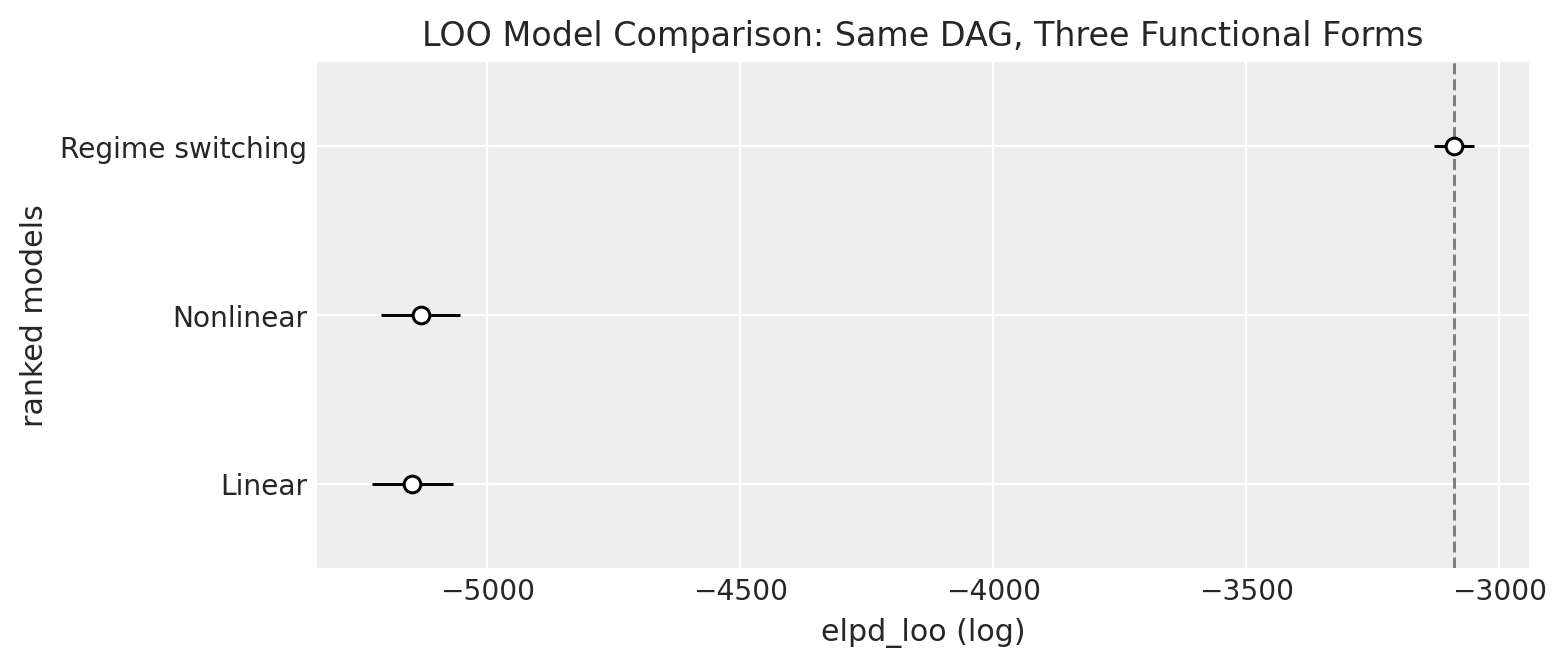

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
az.plot_compare(comparison, ax=ax, insample_dev=False)
ax.set_title("LOO Model Comparison: Same DAG, Three Functional Forms", fontsize=12)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig2_loo_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

Sampling: [DR, ECF, R_eq]


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling: [DR, ECF, R_eq]


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling: [DR, ECF, R_eq]


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

C:\Users\camil\AppData\Local\Temp\ipykernel_103592\4262418342.py:10: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\camil\AppData\Local\Temp\ipykernel_103592\4262418342.py:10: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


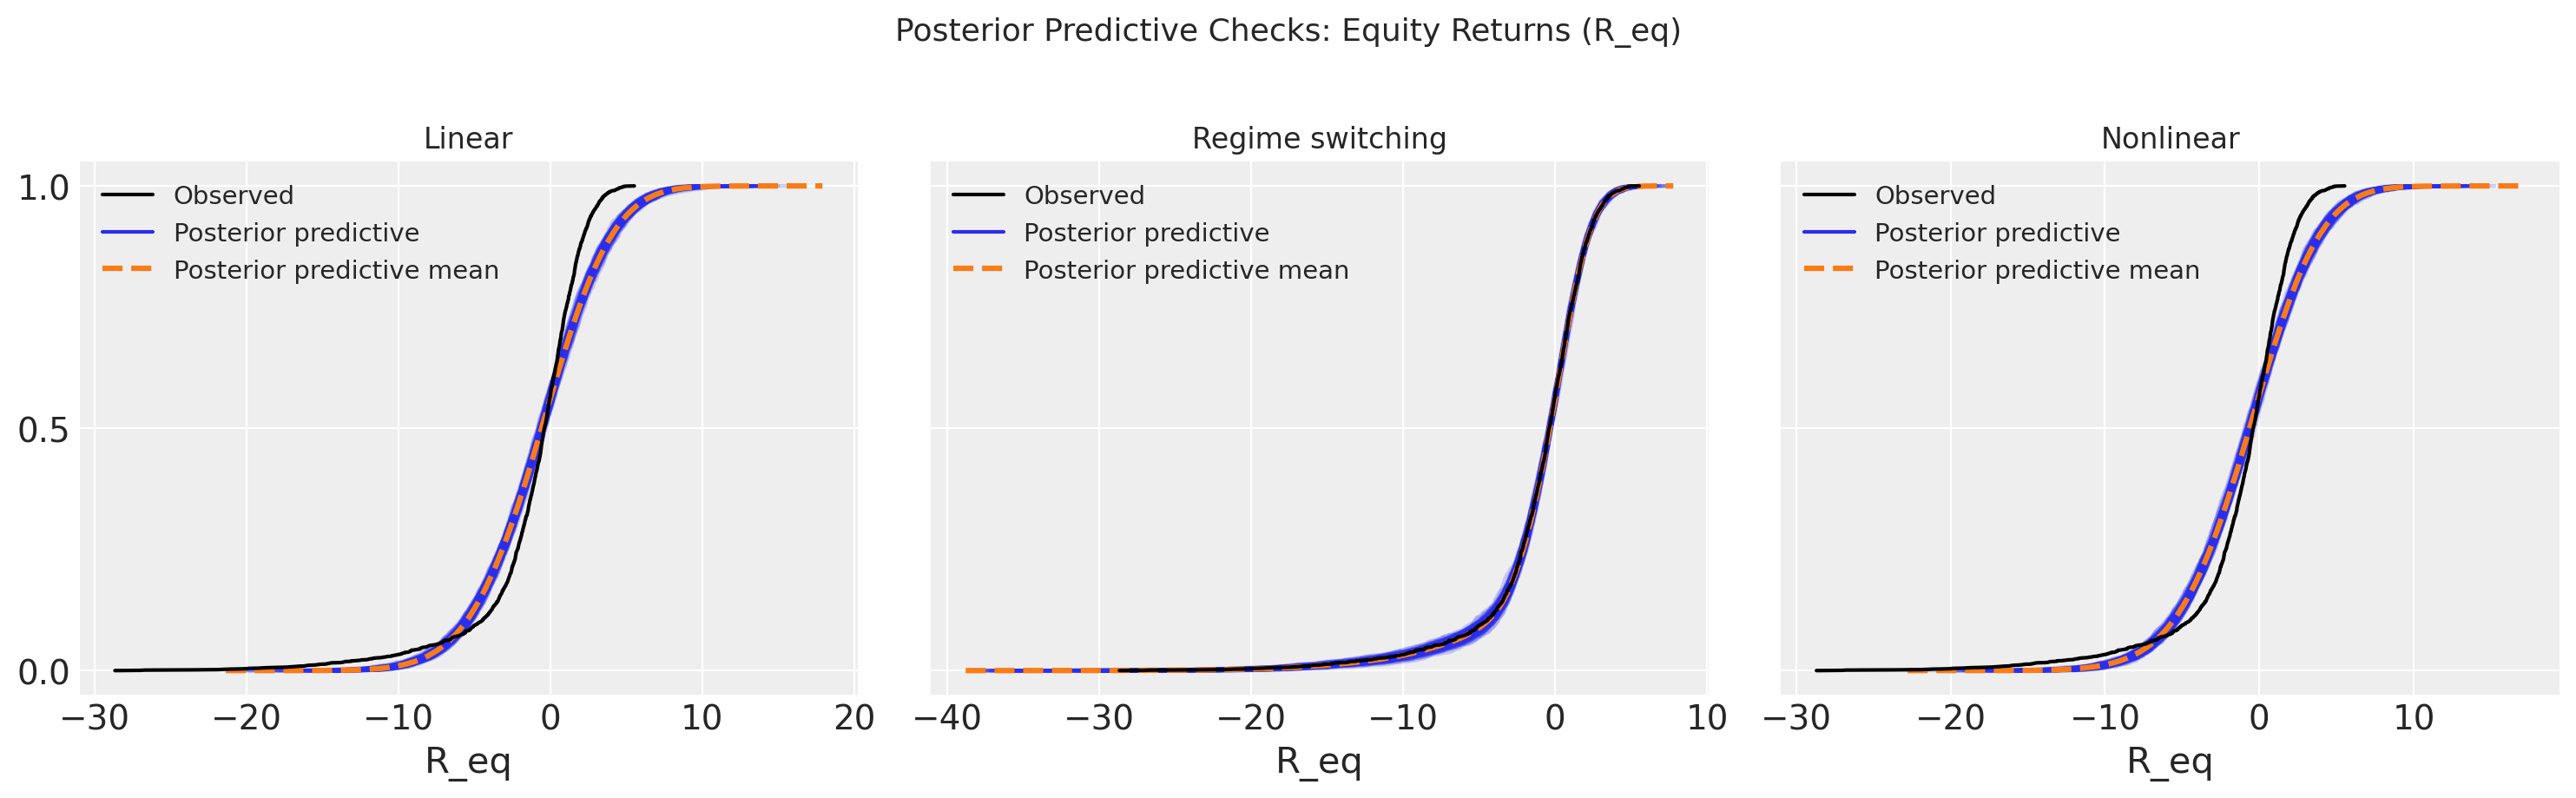

In [12]:
ppc_data = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for i, (name, model) in enumerate(models.items()):
    with model:
        ppc = pm.sample_posterior_predictive(traces[name], random_seed=RANDOM_SEED)
    ppc_data[name] = ppc
    az.plot_ppc(ppc, var_names=["R_eq"], ax=axes[i], num_pp_samples=200, kind="cumulative")
    axes[i].set_title(f"{name}", fontsize=12)
fig.suptitle("Posterior Predictive Checks: Equity Returns (R_eq)", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig3_ppc.png"), dpi=150, bbox_inches="tight")
plt.show()

## Right Form, Right DAG, Extra Edge

The LOO score is a statistical number. The return is the economic consequence.

A simple strategy: predict $R_{eq}$ from each model's posterior mean, go long if the prediction is positive, short if negative, and scale position by normalized confidence.

In [13]:
def compute_strategy_pnl(ppc_obj, actual_req, pnl_scale=1.0):
    pred = ppc_obj.posterior_predictive["R_eq"].mean(dim=["chain", "draw"]).values
    signal = np.sign(pred)
    size = np.clip(np.abs(pred) / np.std(pred), 0, 2.0)
    pnl = signal * size * actual_req * pnl_scale
    return np.cumsum(pnl), pred

pnl_scale = 0.02 / np.std(req_vals)   # normalise to 2% std dev per event
results = {}
for name in models:
    results[name] = compute_strategy_pnl(ppc_data[name], req_vals, pnl_scale=pnl_scale)

C:\Users\camil\AppData\Local\Temp\ipykernel_103592\1867285576.py:30: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


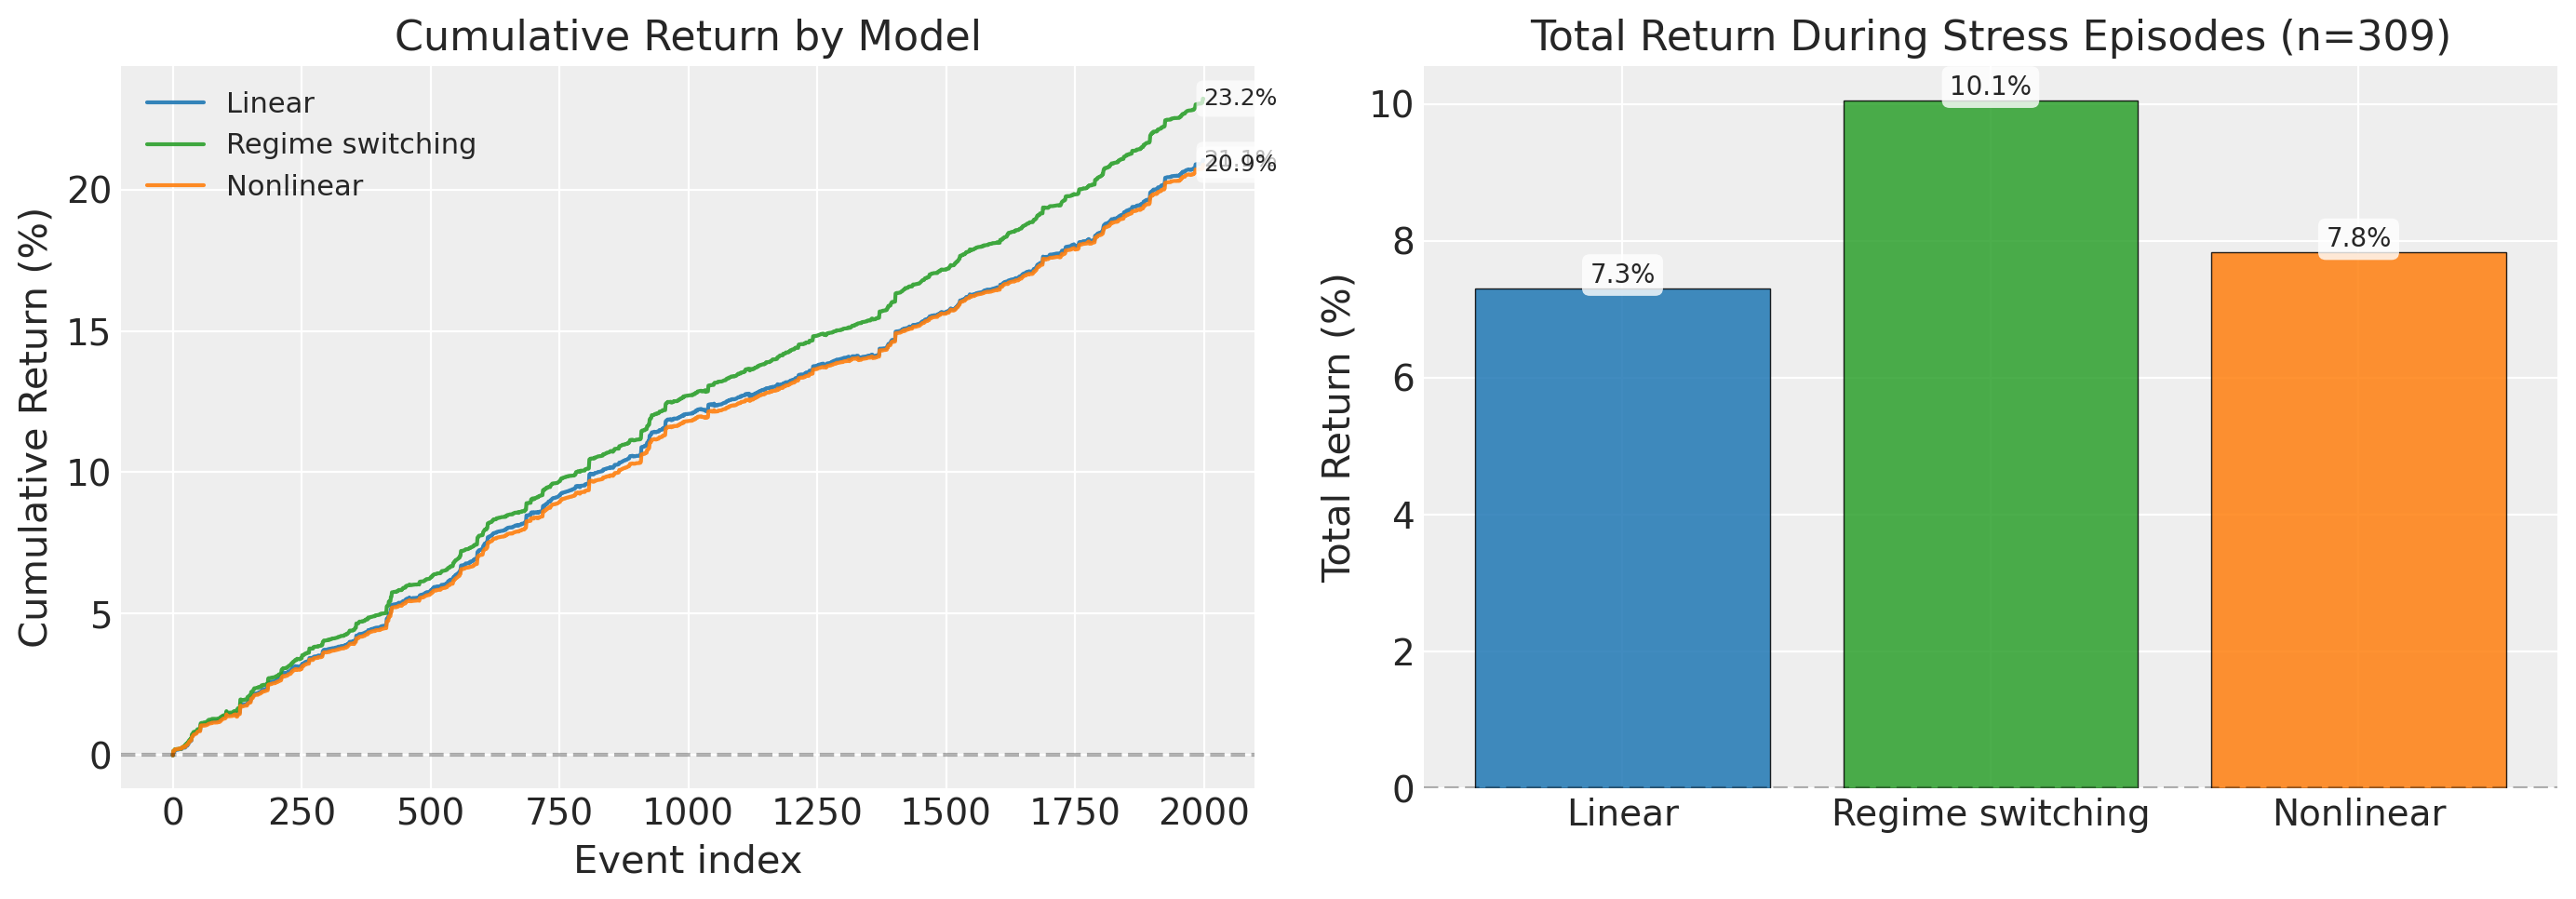

In [14]:
stress_mask = df["stress"].values.astype(bool)
n_stress = int(stress_mask.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_map = {"Linear": "#1f77b4", "Regime switching": "#2ca02c", "Nonlinear": "#ff7f0e"}
for name, (cum_pnl, _) in results.items():
    axes[0].plot(cum_pnl, label=name, alpha=0.9, color=colors_map[name], lw=1.5)
    axes[0].text(len(cum_pnl)-1, cum_pnl[-1], f'{cum_pnl[-1]:.1f}%',
                 fontsize=9, ha='left', va='center',
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor='none'))
axes[0].set(xlabel="Event index", ylabel="Cumulative Return (%)", title="Cumulative Return by Model")
axes[0].legend(fontsize=11)
axes[0].axhline(0, color="black", ls="--", alpha=0.3)

stress_pnl = {}
for name, (_, pred) in results.items():
    signal = np.sign(pred)
    size = np.clip(np.abs(pred) / np.std(pred), 0, 2.0)
    pnl_stress = (signal * size * req_vals * pnl_scale)[stress_mask].sum()
    stress_pnl[name] = float(pnl_stress)
    bar = axes[1].bar(name, pnl_stress, color=colors_map[name], alpha=0.85, edgecolor="black", lw=0.5)
    axes[1].text(bar[0].get_x() + bar[0].get_width()/2, pnl_stress,
                 f'{pnl_stress:.1f}%', ha='center',
                 va='bottom' if pnl_stress > 0 else 'top', fontsize=10,
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='none'))
axes[1].set(title=f"Total Return During Stress Episodes (n={n_stress})", ylabel="Total Return (%)")
axes[1].axhline(0, color="black", ls="--", alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig4_pnl.png"), dpi=150, bbox_inches="tight")
plt.show()

## Parameter Recovery

Does the winning model actually recover the true causal parameters?

C:\Users\camil\AppData\Local\Temp\ipykernel_103592\2607119828.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


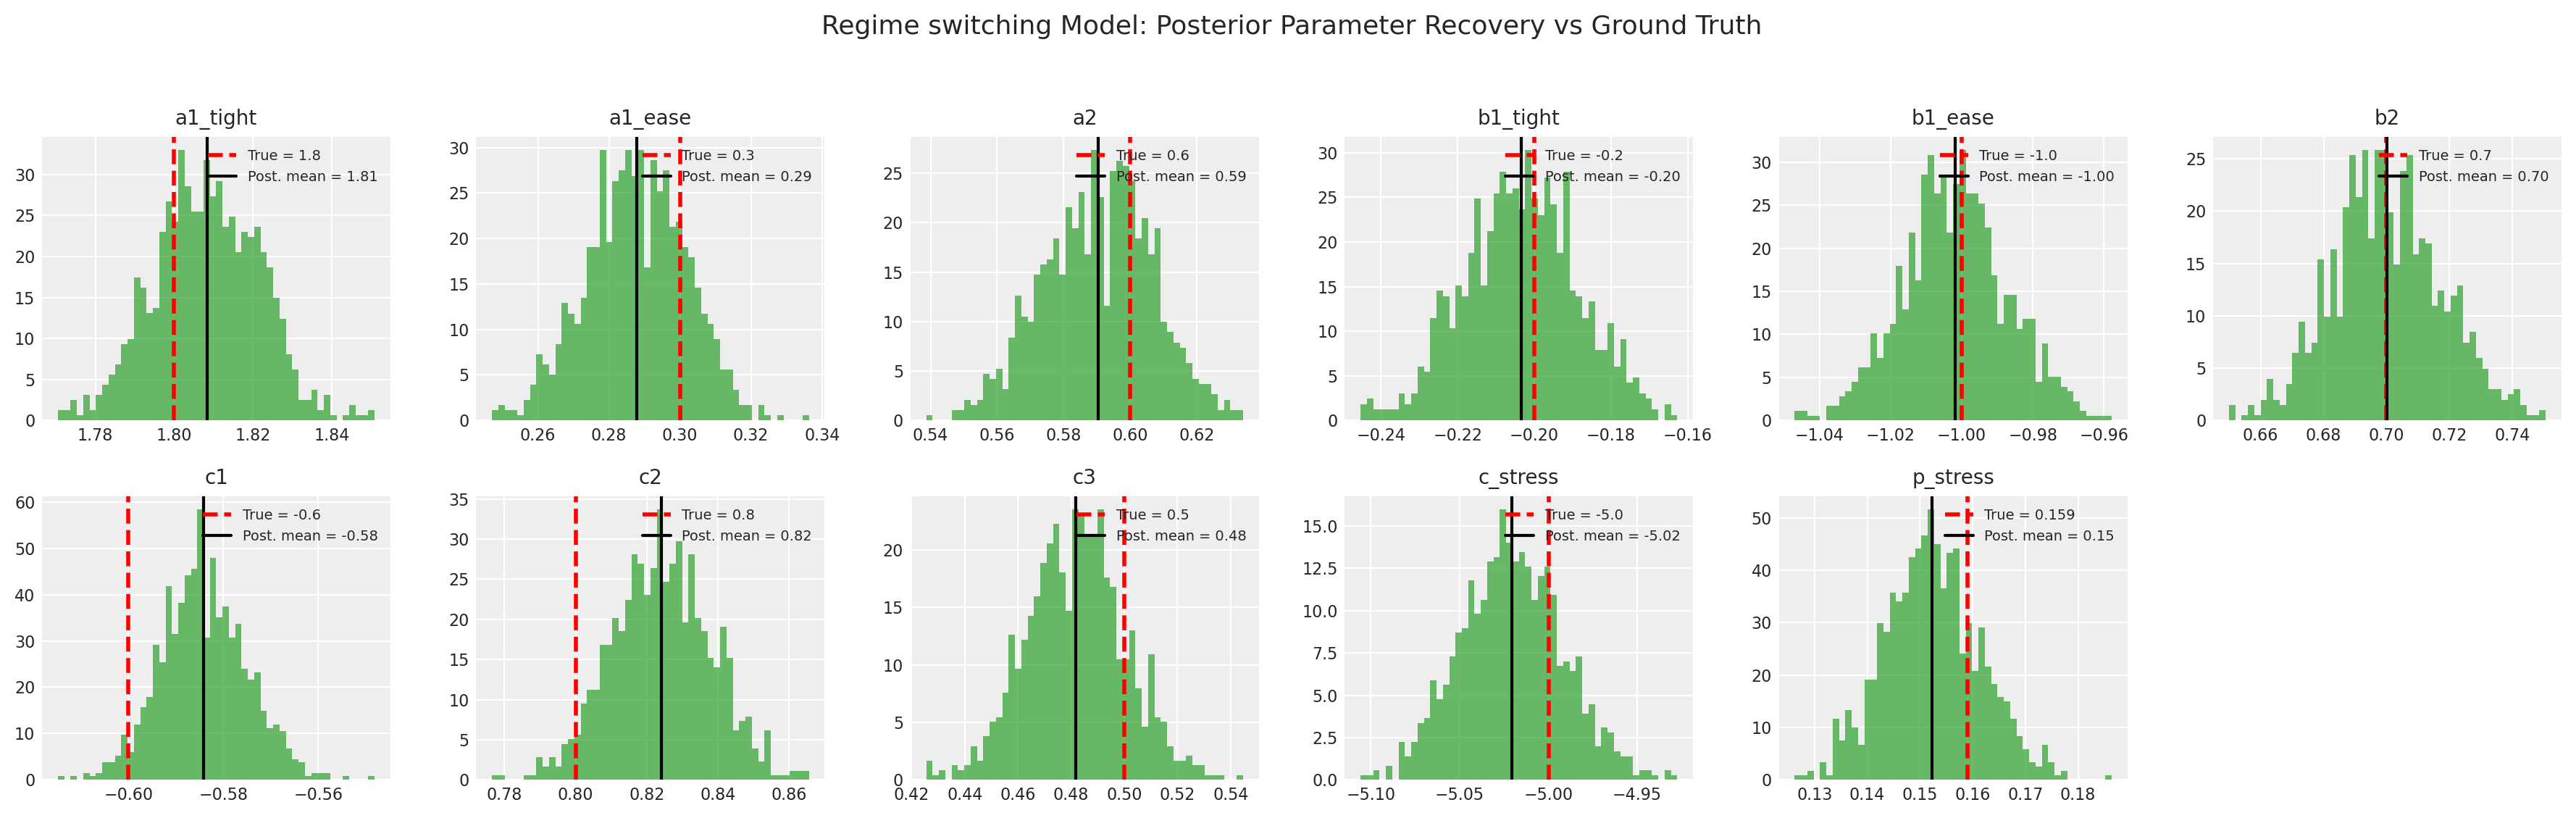

In [15]:
true_params = {
    "a1_tight": 1.8, "a1_ease": 0.3, "a2": 0.6,
    "b1_tight": -0.2, "b1_ease": -1.0, "b2": 0.7,
    "c1": -0.6, "c2": 0.8, "c3": 0.5, "c_stress": -5.0,
    "p_stress": 0.159,
}
param_names = list(true_params.keys())
posterior = traces["Regime switching"].posterior

fig, axes = plt.subplots(2, 6, figsize=(18, 5.5))
axes = axes.flatten()
for ax in axes[len(param_names):]:
    ax.set_visible(False)
for i, pname in enumerate(param_names):
    samples = posterior[pname].values.flatten()
    axes[i].hist(samples, bins=50, density=True, alpha=0.7, color="#2ca02c", edgecolor="none")
    axes[i].axvline(true_params[pname], color="red", ls="--", lw=2, label=f"True = {true_params[pname]}")
    axes[i].axvline(np.mean(samples), color="black", ls="-", lw=1.5, label=f"Post. mean = {np.mean(samples):.2f}")
    axes[i].set_title(pname, fontsize=10)
    axes[i].legend(fontsize=7, loc="upper right")
    axes[i].tick_params(labelsize=8)
fig.suptitle("Regime switching Model: Posterior Parameter Recovery vs Ground Truth", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig5_param_recovery.png"), dpi=150, bbox_inches="tight")
plt.show()

In [16]:
summary_results = {
    "loo_ranking": comparison.index.tolist(),
    "loo_elpd": {k: float(v) for k, v in comparison["elpd_loo"].items()},
    "loo_se": {k: float(v) for k, v in comparison["se"].items()},
    "stress_pnl": stress_pnl,
    "final_cum_pnl": {name: float(cum_pnl[-1]) for name, (cum_pnl, _) in results.items()},
    "n_obs": N,
    "n_stress": n_stress,
}
with open(os.path.join(FIG_DIR, "results.json"), "w") as f:
    json.dump(summary_results, f, indent=2)

print("=== RESULTS SUMMARY ===")
print(f"LOO ranking: {summary_results['loo_ranking']}")
print(f"LOO ELPD: {summary_results['loo_elpd']}")
print(f"Final cumulative P&L: {summary_results['final_cum_pnl']}")
print(f"Stress P&L: {summary_results['stress_pnl']}")
print(f"N stress events: {n_stress}/{N}")
print(f"\nAll figures and results saved to: {FIG_DIR}")

=== RESULTS SUMMARY ===
LOO ranking: ['Regime switching', 'Nonlinear', 'Linear']
LOO ELPD: {'Regime switching': -3089.586783908355, 'Nonlinear': -5131.260823863609, 'Linear': -5148.049442624189}
Final cumulative P&L: {'Linear': 21.050938124293634, 'Regime switching': 23.221565199874338, 'Nonlinear': 20.883396537145448}
Stress P&L: {'Linear': 7.311566193162764, 'Regime switching': 10.057494406031019, 'Nonlinear': 7.8358967575173555}
N stress events: 309/2000

All figures and results saved to: C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\figures


## The Pipeline

1. **Anchor on a candidate DAG** — from theory, literature, or a discovery algorithm. Know its assumptions.
2. **Propose competing functional forms** as PyMC models that all share the same graph.
3. **Fit and compare** with LOO. Let the data rule out misspecified structures.
4. **Check the tails** via posterior predictive checks — that is where misspecification hides.
5. **Test the economic consequence** — P&L simulation, hedging, risk attribution — because the edge from the right form is largest in the tails of the distribution.

Structure is the starting line, not the finish. A DAG without a functional form is a hypothesis without a prediction. PyMC gets you from graph to quantified, decision-ready structural model.